## Simulation Data Preparation

For implementing the training algorithm of ACSSM, I prepared the simple OU process.

OU process have mean reversion and noise property. $-aX_tdt$ term means that the process $X_t$ is exponentially decaying process with reverting to the original point. 

$$
    dX_t = -A_tX_t dt + dW_t
$$


### Data properties

1. shape of tensor
( Batch, Time, Feature ) = (128, 40, 1)

- Batch is the number of distinct time series. So we are dealing with 128 series.

- Time means the irregular time stamp that we collected the data from the original series.

- Feature is the dimension of the observed variables at each time stamp.


### Properties of OU SDE

- the stationary process is ( from FP )
$$
    X_\infty \sim \mathcal{N}(0, \frac{1}{2a})
$$

- Transition distribution ( from OU SDE integration )
$$
    X_{t+\Delta t} \mid X_t = x \sim \mathcal{N}\left( e^{-a\Delta t}x, \frac{1-e^{-2a\Delta t}}{2a} \right)
$$

$$
    X_{t+\Delta t} = e^{-a\Delta t}X_t + \sqrt{\frac{1-e^{-2a\Delta t}}{2a}}Z , \quad Z \sim \mathcal{N}(0,1)
$$


### Observation Model
$$
    Y_{t_i} = X_{t_i} + \epsilon_i, \quad \epsilon_i \sim \mathcal{N}(0, \sigma_{obs}^2)
$$

In [3]:
import torch

def make_1d_ou_data(
        n_series=128, 
        n_times=40, 
        a=0.7,   # mean-reversion coefficient ( how strong it would reverts to the origin. )
        obs_std=0.1, 
        seed=42):
    
    g = torch.Generator().manual_seed(seed)  # random generator defined in torch library.


    # make irregular time stamps and intervals
    """
        torch.rand( 128, 39, generator = g )  :  make ( 128 * 39 ) random numbers in matrix form, using generator g 

        g can be uniform, gaussian , etc.. 

        dt[0] : intervals of the first series.
    """
    dt = 0.05 + 0.15 * torch.rand(
        n_series, n_times - 1, generator=g
    )


    """

        we thinke the matrix as the collection of the time series. 
        ( each row = 1 series )
        ( each column = x-axis = time )

        dim = 0 indicates "the direction of increasing row number". therefore, the direction is from (0i, 1i, 2i, 3i, ..., ni ) 

        dim = 1 indicates "the direction of increasing col number". the direction is from ( i0, i1, i2, i3, ..., in )

        dim = 2 indicates "the direction of increasing 3rd index" .  the direction is from ( ij0, ij1, ij2, ..., ijn)

        
        torch.cumsum(dim = 1)  :  make cummulative sum of a given tensor along dim=1 without changing its shape.

        [ [1,1,1],        [ [1,2,3],
          [1,1,1] ]   ->    [1,2,3]  ]

        
        torch.cat  :  connects multiple tensors along with the dimension.

        tensor1: (128,1)  tensor2 : (128,39)

        torch.cat( [tensor1, tensor2] , dim = 1 )  :  (128,1) + (128,39) = (128, 40) ( col index direction )

          
    """
    # concatenate "0" in front of each series. and time stamps with cumsum of interval.
    times = torch.cat(
        [torch.zeros(n_series, 1), dt.cumsum(dim=1)],
        dim=1,
    )


    # Generate initial state from OU process

    x = torch.zeros(n_series, n_times, 1)  # 128 series and 40 stamps with all zero.

    """
        x[:,0] = (128,1) the first time stamp of every series

        stationary distribution of OU process from FP equation.   N(0, 1/2a) = 1/sqrt(2a) * N(0,1)
    """
    x[:, 0] = (
        torch.randn(n_series, 1, generator=g)
        / (2 * a) ** 0.5
    )   


    # Calculate X_{t+delta t} from transition distribution
    """
        dt[:, 0]  :  (128,)  t = 0 for 128 series

        dt[:, 0:1] :  (128,1) 2 dim tensor

        we use expm1 := e^z - 1  for small z. because of the error at z~0
    """
    for i in range(n_times - 1):
        gap = dt[:, i:i + 1]
        decay = torch.exp(-a * gap)
        variance = -torch.expm1(-2 * a * gap) / (2 * a)

        # transition dist ( int of dX_t )
        x[:, i + 1] = (
            decay * x[:, i]
            + variance.sqrt()
            * torch.randn(n_series, 1, generator=g)
        )

    """
        This explains observation model with independent noise.
    """
    target = x + obs_std * torch.randn(
        x.shape, generator=g
    )

    # 약 30%의 관측을 입력에서 숨김
    obs_mask = torch.rand(
        n_series, n_times, 1, generator=g
    ) > 0.3
    obs_mask[:, :2] = True

    obs = torch.where(
        obs_mask, target, torch.zeros_like(target)
    )

    return {
        "times": times,
        "obs": obs,
        "obs_mask": obs_mask,
        "target": target,
        "latent_truth": x,
    }

data = make_1d_ou_data()

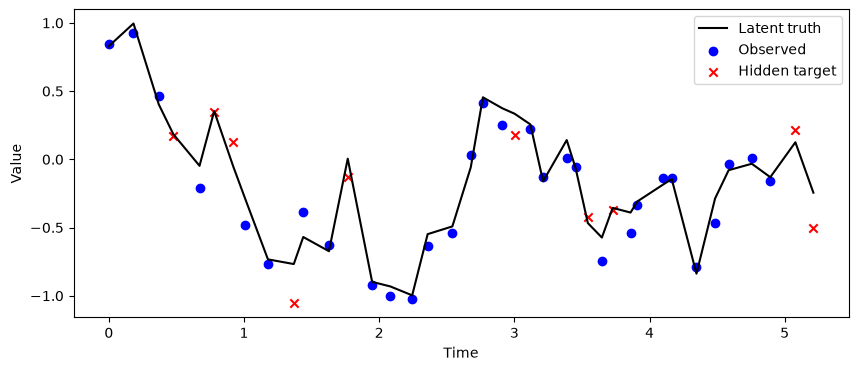

In [5]:
import matplotlib.pyplot as plt

t = data["times"][0].numpy()
x = data["latent_truth"][0, :, 0].numpy()
y = data["target"][0, :, 0].numpy()
mask = data["obs_mask"][0, :, 0].numpy()

plt.figure(figsize=(10, 4))

plt.plot(t, x, label="Latent truth", color="black")

plt.scatter(
    t[mask], y[mask],
    label="Observed", color="blue"
)

plt.scatter(
    t[~mask], y[~mask],
    label="Hidden target", color="red",
    marker="x"
)

plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.show()

## Simple d-dimensional OU process 

Generalize the previous 1-D OU process, consider d-dimensional OU process with size (128, 40, d)

$$
    d \mathrm{X_t} = -K( \mathrm{X}_t - \mathrm{\mu} ) dt + G d\mathrm{W}_t, \quad \mathrm{X}_t, \mathrm{W}_t, \mathrm{\mu} \in \mathbb{R}^d, \quad K = \text{diag}(a_1, a_2, \dots, a_d), \;G = \text{diag}(\sigma_1, \sigma_2, \dots, \sigma_d)
$$

This diagonal OU process is linearly decoupled to d linear OU process ( each components are independetly decoupled. )

In [10]:
import torch

def make_ou_data(
        n_series : int = 128, 
        n_times : int = 40, 
        dim : int = 3, 
        *,
        a : torch.Tensor | None = None ,   # mean-reversion coefficient ( how strong it would reverts to the origin. )
        mu : torch.Tensor | None = None ,
        sigma : torch.Tensor | None = None,
        obs_std : float = 0.1, 
        seed: int =42 
        ) -> dict:


        # create tensors for K, mu, G 
        if a is None:
                a = torch.ones(dim)
        if mu is None:
                mu = torch.zeros(dim)
        if sigma is None:
                sigma = torch.ones(dim)

        assert isinstance(a, torch.Tensor) and a.shape == (dim,)
        assert isinstance(mu,torch.Tensor) and mu.shape == a.shape
        assert isinstance(sigma, torch.Tensor) and sigma.shape == a.shape


        # make irregular time stamp ( seen 70% + unseen 30% )

        g = torch.Generator().manual_seed(seed)



        dt = 0.05 + 0.15*torch.rand(n_series , n_times-1 , generator= g ) # 0.05 < dt < 0.20 uniform sampling

        times = torch.cat( [torch.zeros(n_series,1) , torch.cumsum(dt, dim=1) ], dim = 1)


        # from given distribution of d-dim OU process, make observation sampling

        x = torch.zeros(n_series, n_times, dim)

        a_expand = a.unsqueeze(0).expand(n_series,-1)
        sigma_expand = sigma.unsqueeze(0).expand(n_series,-1)
        mu_expand = mu.unsqueeze(0).expand(n_series,-1)


        x[:,0,:] = mu_expand + torch.sqrt( sigma_expand**2 / 2*a_expand ) * torch.randn(n_series,dim, generator=g)


        for t_i in range(n_times-1):

                variance = (sigma_expand**2 / (2*a_expand) )* (-1) * (torch.expm1(-2*a_expand*dt[:,t_i:t_i+1]))
                decay = torch.exp(-a_expand * dt[:,t_i:t_i+1])

                x[:, t_i + 1,:] = mu_expand + decay * (x[:, t_i, :] - mu_expand) + torch.sqrt(variance) * torch.randn(n_series,dim, generator = g)



        # observation model ( obs = x + obs_std * rand )
        """
        latent_truth :  given SDE, the truth latex vector X_t

        target :  truth X_t + noisy observation factor =  observation o_t in paper.

        latent_truth : shallow copy ( reference )
        target : deep copy ( new tensor )
        """
        latent_truth = x  
        target = x + obs_std * torch.randn(n_series, n_times, dim, generator=g)


        assert target.shape == (n_series,n_times,dim)




        # masking 30% of unseen data
        """
        tensor > 1  =>  making boolean tensor ( boolean masking ) consisting True element where the element is larger than 1

        tensor[:, :2, : ]  => (128, 2, 3) type of tensor starting from initial to (2-1 = 1)
        """
        obs_mask = torch.rand(n_series, n_times , generator=g) > 0.3
        target_mask = torch.zeros(n_series, n_times) == 0

        obs_mask[:, :2] = True

        """
        at first, use unsqueeze to make extra dim ( 128, 40 ) -> (128, 40, 1)
        ( -1 : add another dim at the last position )

        then repeat ( expand ) using this tensor  (128, 40, 1) -> (128, 40, 3)

        expand (-1,-1, 3) : maintain the dim of the row and col. and expand the dim of last dim.
        """
        obs = torch.where(
                obs_mask.unsqueeze(-1),
                target,
                torch.zeros_like(target)
        )


        dataset = {
                "times" : times,
                "observation" : obs,
                "obs_mask" : obs_mask,
                "target" : target,
                "target_mask" : target_mask,
                "latent_truth" : latent_truth

        }

        return dataset




In [11]:
for d in (2, 3, 5):
    data = make_ou_data(dim=d)

    x = data["latent_truth"]
    t = data["times"]
    obs = data["observation"]
    mask = data["obs_mask"]
    target = data["target"]

    assert x.shape == (128, 40, d)
    assert torch.isfinite(x).all()
    assert (t[:, 1:] > t[:, :-1]).all()
    assert torch.all(obs[~mask] == 0)
    assert torch.equal(obs[mask], target[mask])

print("All tests passed!")

All tests passed!
